### **Template Matching**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/09_Template_Matching.ipynb)

> **Template matching** slides a small image (the template) over a larger one and scores the similarity at every position. It works well when the object looks almost the same as the template, but it is **not scale-invariant**: a logo at a different size scores poorly. This notebook finds a logo at its best scale and then detects several logos with a **multi-scale search** and **non-maximum suppression (NMS)**.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

#### **01. Single Match and the Scale Problem**

With `TM_CCOEFF_NORMED`, the best match is the **maximum** of the result map (1.0 = perfect). For `TM_SQDIFF` methods, it is the minimum. Here the template is larger than the logo on the cup, so the score at the original size is weak; resizing the template finds a much stronger match.

Best score at the original size: 0.26
Best score over scales: 0.76 at scale 0.75


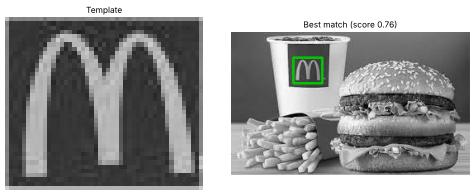

In [2]:
# Compare the best score at the original size with the best score over several scales
scene = load_image("A_mac_01.jpg", cv2.IMREAD_GRAYSCALE)
template = load_image("T_mac.jpg", cv2.IMREAD_GRAYSCALE)

def best_match(image, tmpl, scales):
    best = (-1, None, None, None)
    for scale in scales:
        resized = cv2.resize(tmpl, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)
        if resized.shape[0] > image.shape[0] or resized.shape[1] > image.shape[1]:
            continue
        _, score, _, location = cv2.minMaxLoc(cv2.matchTemplate(image, resized, cv2.TM_CCOEFF_NORMED))
        if score > best[0]:
            best = (score, location, resized.shape, scale)
    return best

score_original = best_match(scene, template, [1.0])[0]
score, (x, y), (h, w), scale = best_match(scene, template, np.linspace(0.5, 2.0, 31))
print(f"Best score at the original size: {score_original:.2f}")
print(f"Best score over scales: {score:.2f} at scale {scale:.2f}")

result = cv2.cvtColor(scene, cv2.COLOR_GRAY2BGR)
cv2.rectangle(result, (x, y), (x + w, y + h), (0, 200, 0), 2)
show([template, result], ["Template", f"Best match (score {score:.2f})"], size=(10, 4))

#### **02. Multiple Matches: Multi-Scale Search and NMS**

Every position above a threshold is a candidate, at every scale. Neighboring positions of the same logo all pass the threshold, so **NMS** keeps only the highest-scoring box among overlapping ones. This replaces the original approach of a hand-picked template resize (1/1.3) and comparison with only the previous box.

Candidates above 0.6: 73 | after NMS: 2
Logo 1: x=140, y=39, size=61x50, score=0.75
Logo 2: x=445, y=47, size=57x46, score=0.72


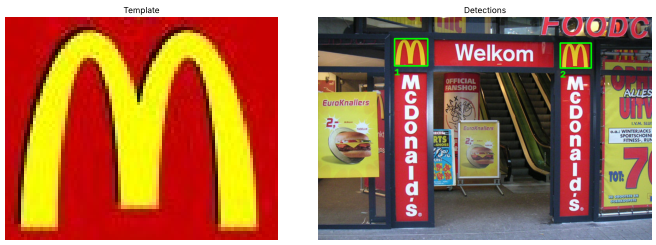

In [3]:
# Multi-scale detection with non-maximum suppression
scene = load_image("A_mac_11.jpg")
template = load_image("T_mac2.jpg")
THRESHOLD = 0.6

boxes, scores = [], []
for scale in np.linspace(0.3, 1.2, 19):
    resized = cv2.resize(template, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)
    h, w = resized.shape[:2]
    if h < 10 or h > scene.shape[0] or w > scene.shape[1]:
        continue
    result_map = cv2.matchTemplate(scene, resized, cv2.TM_CCOEFF_NORMED)
    for y, x in zip(*np.where(result_map >= THRESHOLD)):
        boxes.append([int(x), int(y), w, h])
        scores.append(float(result_map[y, x]))

keep = np.array(cv2.dnn.NMSBoxes(boxes, scores, THRESHOLD, 0.3)).ravel()
print(f"Candidates above {THRESHOLD}: {len(boxes)} | after NMS: {len(keep)}")
detections = scene.copy()
for n, i in enumerate(keep, 1):
    x, y, w, h = boxes[i]
    print(f"Logo {n}: x={x}, y={y}, size={w}x{h}, score={scores[i]:.2f}")
    cv2.rectangle(detections, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(detections, str(n), (x, y + h + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
show([template, detections], ["Template", "Detections"], size=(14, 5))

#### **Key Takeaways**

* Normalized methods (`*_NORMED`) give comparable scores across positions and scales.
* Search over scales when the object size varies, and use NMS to merge duplicate hits.
* For rotation, perspective, or appearance changes, use feature matching (ORB, SIFT) or a trained detector instead.